In this Jupyterbook, we will see a way to decode the neuronal activity.
We will use simulated data from single neurons recording from the Primary somatosensory cortex during tactile stimulations (stimulation of finger tip 2, 3)

To Do before the next session, answer the following questions

- what is decoding ? 
- why using an artificial neural network to decode the information contained in single unit data ? 
- why should we use a multi-layer network and not a simple perceptron ? 

in this NB, i used the `perceptron` from the library scikit-learn




In [16]:
import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import random
import warnings
import sys

import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
plt.style.use('dark_background')


# here is the code to generate the data for the two neurons
# the activity are summarized with 0 and 1, where 0 means 
# no activity and 1 means activity of the neuron in a given time window. 
# each row represent a trial and each column represent a neuron.

# stim contains the stimulus information,
# where 0 means  stimulus of digit 2 and 1 means stimulus of digit 3.

# the function np.random.choice is used to generate the activity 
# of the neurons and allow to set the probability of activity for each neuron
# in response to the stimulus.

neuron1 = np.zeros(1000) 
neuron1[0:500] = np.random.choice([0, 1], size=500, p=[0.25, 0.75])
neuron1[500:] = np.random.choice([0, 1], size=500, p=[0.75, 0.25])
    
neuron2 = np.zeros(1000)
neuron2[0:500] = np.random.choice([0, 1], size=500, p=[0.75, 0.25])
neuron2[500:] = np.random.choice([0, 1], size=500, p=[0.25, 0.75])

neuronpop=np.hstack((neuron1, neuron2))
Neuronpop=np.reshape(neuronpop, (2, 1000)).T

stim=np.zeros(1000)
stim[0:500] = 0
stim[500:] = 1
stim_df = pd.DataFrame(stim, columns=['stimulus'])

Neuronpop_df = pd.DataFrame(Neuronpop, columns=['neuron1', 'neuron2'])


Accuracy: 0.70


Text(0.5, 1.0, 'Perceptron Confusion Matrix')

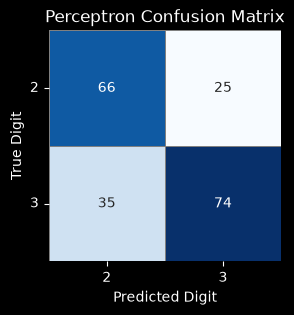

In [ ]:
## perceptron for N neurons and 2 classes
### using sklearn Perceptron

from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split

X=np.reshape(neuron2.T, (-1, 1)) #Neuronpop

y=stim

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Create and train the Perceptron model
perceptron = Perceptron()

perceptron.fit(X_train, y_train)


# Make predictions on the test set
y_pred = perceptron.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

fig, ax = plt.subplots(figsize=(3,3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,linewidths=0.5, linecolor='gray')
ax.set_xticklabels(['2','3'])
ax.set_yticklabels(['2','3'], rotation=0)
ax.set_xlabel('Predicted Digit')
ax.set_ylabel('True Digit')
ax.set_title('Perceptron Confusion Matrix')


